# Decentralized Hiking AI
## 01 - Real Dataset Audit

**Research Component:** Context-Aware Offline Resource Recommendation

### Objective

This notebook audits the real datasets collected for the Context-Aware Offline Resource Recommendation component.

The purpose is to:

- verify that required dataset files exist;
- inspect dataset dimensions and columns;
- identify missing values;
- validate geospatial information;
- inspect trail, terrain, weather, emergency, and connectivity-related data;
- distinguish observed data from derived features;
- identify unavailable variables before machine-learning preparation.

### Data Policy

Only real collected or legitimately derived data is used.

No synthetic or mock observations are introduced into the research dataset.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Find project root automatically
current = Path.cwd().resolve()

if current.name == "notebooks":
    PROJECT_ROOT = current.parent.parent
elif (current / "research").exists():
    PROJECT_ROOT = current
else:
    raise FileNotFoundError(
        "Could not locate project root. "
        f"Current working directory: {current}"
    )

RESEARCH_DIR = PROJECT_ROOT / "research"
DATASET_DIR = RESEARCH_DIR / "dataset"

RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"
METADATA_DIR = DATASET_DIR / "metadata"
LABELS_DIR = DATASET_DIR / "labels"

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("Exists       :", DATASET_DIR.exists())

Project root : /Users/mirshad/Desktop/Decentralized-Hiking-AI
Dataset      : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset
Exists       : True


In [3]:
all_files = sorted([
    file for file in DATASET_DIR.rglob("*")
    if file.is_file()
])

print(f"Total files found: {len(all_files)}")
print()

for file in all_files:
    relative_path = file.relative_to(DATASET_DIR)
    size_mb = file.stat().st_size / (1024 ** 2)

    print(f"{str(relative_path):75} {size_mb:8.2f} MB")

Total files found: 164

README.md                                                                       0.01 MB
collection_report.md                                                            0.00 MB
labels/labeling_methodology.md                                                  0.00 MB
labels/resource_catalog.csv                                                     0.00 MB
metadata/connectivity_methodology.md                                            0.00 MB
metadata/copernicus_aws_readme.html                                             0.01 MB
metadata/data_dictionary.csv                                                    0.01 MB
metadata/dataset_sources.csv                                                    0.06 MB
metadata/download_log.jsonl                                                     0.03 MB
metadata/elevation_inventory.csv                                                0.00 MB
metadata/file_manifest.csv                                                      0.02 MB
metadata

In [4]:
knuckles_files = [
    file for file in all_files
    if "knuckles" in file.name.lower()
]

print(f"Knuckles-related files: {len(knuckles_files)}")
print()

for file in knuckles_files:
    print(file.relative_to(DATASET_DIR))

Knuckles-related files: 19

processed/elevation/knuckles_trail_points.csv
processed/elevation/knuckles_trail_summary.csv
processed/trails/knuckles_candidate_paths.geojson
processed/weather/knuckles_0_hourly.csv
processed/weather/knuckles_1_hourly.csv
processed/weather/knuckles_2_hourly.csv
processed/weather/knuckles_3_hourly.csv
processed/weather/knuckles_4_hourly.csv
raw/connectivity/knuckles_osm_communication_structures.geojson
raw/emergency/knuckles_facilities.geojson
raw/emergency/knuckles_facilities_osm.json
raw/trails/knuckles.overpassql
raw/trails/knuckles_hiking_relations.json
raw/trails/knuckles_pbf_extract.geojson
raw/weather/knuckles_0_2021_2025.json
raw/weather/knuckles_1_2021_2025.json
raw/weather/knuckles_2_2021_2025.json
raw/weather/knuckles_3_2021_2025.json
raw/weather/knuckles_4_2021_2025.json


In [5]:
print("PROCESSED DATA")
print("=" * 70)

for path in sorted(PROCESSED_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(DATASET_DIR))

PROCESSED DATA
processed/.DS_Store
processed/elevation/adams_peak_trail_points.csv
processed/elevation/adams_peak_trail_summary.csv
processed/elevation/ella_trail_points.csv
processed/elevation/ella_trail_summary.csv
processed/elevation/haputale_trail_points.csv
processed/elevation/haputale_trail_summary.csv
processed/elevation/horton_plains_trail_points.csv
processed/elevation/horton_plains_trail_summary.csv
processed/elevation/knuckles_trail_points.csv
processed/elevation/knuckles_trail_summary.csv
processed/elevation/meemure_trail_points.csv
processed/elevation/meemure_trail_summary.csv
processed/elevation/namunukula_trail_points.csv
processed/elevation/namunukula_trail_summary.csv
processed/elevation/riverston_trail_points.csv
processed/elevation/riverston_trail_summary.csv
processed/elevation/sigiriya_pidurangala_trail_points.csv
processed/elevation/sigiriya_pidurangala_trail_summary.csv
processed/elevation/sinharaja_trail_points.csv
processed/elevation/sinharaja_trail_summary.csv

In [6]:
trail_candidates = [
    file for file in knuckles_files
    if file.suffix.lower() in [".geojson", ".gpkg"]
    and "trail" in str(file).lower()
]

print("Possible Knuckles trail files:")

for i, file in enumerate(trail_candidates):
    print(i, file.relative_to(DATASET_DIR))

Possible Knuckles trail files:
0 processed/trails/knuckles_candidate_paths.geojson
1 raw/trails/knuckles_pbf_extract.geojson


In [7]:
processed_trails = [
    f for f in trail_candidates
    if "processed" in f.parts
]

if processed_trails:
    KNuckles_TRAIL_FILE = processed_trails[0]
elif trail_candidates:
    KNuckles_TRAIL_FILE = trail_candidates[0]
else:
    raise FileNotFoundError("No Knuckles trail GeoJSON found.")

trails = gpd.read_file(KNuckles_TRAIL_FILE)

print("Loaded:", KNuckles_TRAIL_FILE.relative_to(DATASET_DIR))
print("Rows:", len(trails))
print("Columns:", len(trails.columns))
print("CRS:", trails.crs)

Loaded: processed/trails/knuckles_candidate_paths.geojson
Rows: 559
Columns: 38
CRS: EPSG:4326


In [8]:
print("TRAIL COLUMNS")
print("=" * 50)

for column in trails.columns:
    print(column)

TRAIL COLUMNS
id
osm_type
osm_id
tags
access
bicycle
bridge
crossing
crossing:markings
cutting
description
embankment
foot
footway
highway
horse
incline
informal
lanes
layer
lit
maxspeed
motor_vehicle
motorcycle
mtb:scale
mtb:scale:uphill
name
note
sac_scale
smoothness
surface
tracktype
wheelchair
width
verified_hiking_trail
length_km
hiking_relation_ids
geometry


In [9]:
trails.head()

,id,osm_type,osm_id,tags,access,bicycle,bridge,crossing,crossing:markings,cutting,...,sac_scale,smoothness,surface,tracktype,wheelchair,width,verified_hiking_trail,length_km,hiking_relation_ids,geometry
0,way/100146710,way,100146710,"{ ""highway"": ""footway"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,1.654853,[ ],"LINESTRING (80.71194 7.41703, 80.71188 7.4173,..."
1,way/100146711,way,100146711,"{ ""highway"": ""track"", ""maxspeed"": ""25"", ""motor...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,4.966901,[ ],"LINESTRING (80.69633 7.42838, 80.6967 7.42826,..."
2,way/100146901,way,100146901,"{ ""highway"": ""path"", ""note"": ""Only for Mountai...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.859729,[ ],"LINESTRING (80.71186 7.43304, 80.71182 7.43317..."
3,way/100148512,way,100148512,"{ ""highway"": ""track"", ""maxspeed"": ""10"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.995269,[ ],"LINESTRING (80.71059 7.42809, 80.71073 7.4281,..."
4,way/100149325,way,100149325,"{ ""highway"": ""footway"", ""note"": ""Only for Moun...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.646777,[ ],"LINESTRING (80.71048 7.44174, 80.71058 7.44228..."


In [10]:
print("Geometry types:")
print(trails.geometry.geom_type.value_counts())

print()
print("Missing geometries:", trails.geometry.isna().sum())
print("Empty geometries:", trails.geometry.is_empty.sum())
print("Invalid geometries:", (~trails.geometry.is_valid).sum())

Geometry types:
LineString    559
Name: count, dtype: int64

Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0


In [11]:
missing = pd.DataFrame({
    "missing_count": trails.isna().sum(),
    "missing_percent": (trails.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    "missing_percent",
    ascending=False
)

missing

,missing_count,missing_percent
cutting,558,99.82
footway,558,99.82
sac_scale,558,99.82
mtb:scale,558,99.82
crossing,558,99.82
crossing:markings,558,99.82
lit,558,99.82
description,558,99.82
embankment,558,99.82
mtb:scale:uphill,558,99.82


In [12]:
if "highway" in trails.columns:
    print(trails["highway"].value_counts(dropna=False))
else:
    print("No 'highway' column found.")

highway
track        289
footway      125
path         124
steps         20
bridleway      1
Name: count, dtype: int64


count    559.000000
mean       0.582324
std        0.967829
min        0.005793
25%        0.099732
50%        0.243791
75%        0.644812
max        9.178720
Name: length_km, dtype: float64


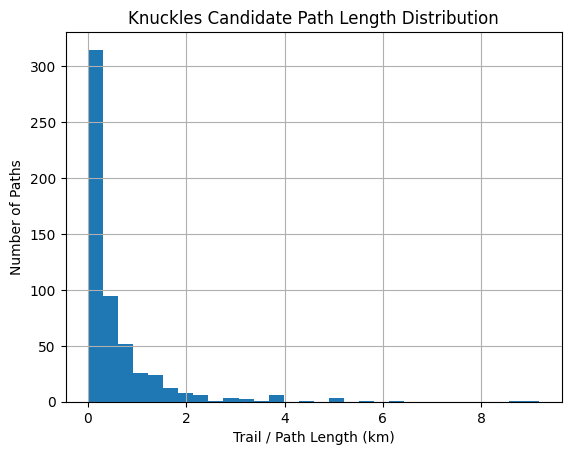

In [13]:
if "length_km" in trails.columns:
    print(trails["length_km"].describe())
    
    trails["length_km"].hist(bins=30)
    plt.xlabel("Trail / Path Length (km)")
    plt.ylabel("Number of Paths")
    plt.title("Knuckles Candidate Path Length Distribution")
    plt.show()
else:
    print("length_km is not available yet.")